# Module 1 — Notebook 03: Pseudobulk DESeq2 + anti-TNF non-response module

**Question.** Within each major cell population of the ulcerative colitis colon (Smillie et al., Cell 2019),
which genes change in inflamed vs healthy tissue — and are the two populations linked to anti-TNF
non-response (inflammatory fibroblasts and OSM+ inflammatory monocytes) expanded and activated in disease?

**Method.** Aggregate raw counts per Subject x condition x author cell label (pseudobulk), then run
DESeq2 (pydeseq2) per cell label, contrast Inflamed vs Healthy. NOTE: in this file the
"Sample" column is a processing-batch code (EpiB, LPB, ...), NOT a sample ID — the
replicate unit is Subject x condition (UC subjects contribute paired inflamed and
non-inflamed biopsies). A paired/mixed model is the refinement, noted for later).

**Module.** Inflammatory fibroblasts (IL11 / IL13RA2 program) and inflammatory monocytes
(OSM / IL1B axis) were tied to anti-TNF resistance in Smillie 2019 and Martin et al., Cell 2019.
Here: (1) their abundance per sample by condition, (2) their program scores by condition.

Analyses of public datasets; all data credited to original authors.


In [8]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import scanpy as sc
import pydeseq2
print("scanpy", sc.__version__, "| pydeseq2", pydeseq2.__version__)

# Load the QC object from notebook 01 (full gene set + raw counts layer).
# Pseudobulk uses the author's cell labels, so the scVI object is not needed here.
cands = [
    os.path.expanduser("~/Documents/immune-endotypes/data/smillie_uc/adata_qc.h5ad"),
    "../../data/smillie_uc/adata_qc.h5ad",
    "adata_qc.h5ad",
]
path = next(p for p in cands if os.path.exists(p))
adata = sc.read_h5ad(path)
adata.obs = adata.obs.rename(columns={"Health": "condition", "Location": "site", "Cluster": "author_label"})
print(adata)
print(adata.obs["condition"].value_counts())


scanpy 1.11.5 | pydeseq2 0.4.12
AnnData object with n_obs × n_vars = 351952 × 18172
    obs: 'Origin', 'Subject', 'Sample', 'site', 'Replicate', 'condition', 'author_label', 'nGene', 'nUMI', 'Major_l1', 'Major_l2', 'Major_l3', 'Major_l4', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'leiden_0.5'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'leiden_0.5', 'leiden_0.5_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'
condition
Non-inflamed    124614
Inflamed        122401
Healthy         104937
Name: coun

In [9]:
# Samples per condition, and the cell labels we will test
print(adata.obs.groupby("condition")["Sample"].nunique())
print(adata.obs["author_label"].nunique(), "author labels")
print(adata.obs["Subject"].nunique(), "subjects |", adata.obs["Sample"].nunique(), "samples")


condition
Healthy          4
Inflamed        10
Non-inflamed    14
Name: Sample, dtype: int64
51 author labels
30 subjects | 24 samples


## 1. Pseudobulk aggregation

Sum raw counts per Subject x condition x author_label (sparse indicator-matrix multiply).
Groups with < 20 cells are dropped.


In [10]:
import scipy.sparse as sp

counts = adata.layers["counts"].tocsr()
obs = adata.obs
key = (obs["Subject"].astype(str) + "|" + obs["condition"].astype(str)
       + "|" + obs["author_label"].astype(str))
codes, uniques = pd.factorize(key)
ind = sp.csr_matrix(
    (np.ones(len(codes), dtype=np.float32), (codes, np.arange(len(codes)))),
    shape=(len(uniques), len(codes)),
)
pb = ind @ counts  # groups x genes
pb_df = pd.DataFrame.sparse.from_spmatrix(pb, index=uniques, columns=adata.var_names)

meta_rows = []
for u in uniques:
    subject, condition, label = u.split("|", 2)
    meta_rows.append({
        "group": u, "Subject": subject, "condition": condition,
        "label": label, "n_cells": int((key == u).sum()),
    })
meta = pd.DataFrame(meta_rows).set_index("group")
meta = meta[meta["n_cells"] >= 20]
pb_df = pb_df.loc[meta.index]
print(pb_df.shape[0], "pseudobulk groups kept")
print(meta.groupby(["label", "condition"]).size().unstack(fill_value=0).head(10))


1380 pseudobulk groups kept
condition              Healthy  Inflamed  Non-inflamed
label                                                 
Best4+ Enterocytes          10         6            11
CD4+ Activated Fos-hi       12        16            17
CD4+ Activated Fos-lo       12        14            16
CD4+ Memory                 12        17            15
CD4+ PD1+                    1         3             1
CD69+ Mast                  11        18            16
CD69- Mast                   1         0             1
CD8+ IELs                   11        10            14
CD8+ IL17+                   2         3             3
CD8+ LP                     12        17            16


## 2. DESeq2 per cell label — Inflamed vs Healthy

A label is tested when it has >= 3 Healthy and >= 3 Inflamed samples.
Genes kept per label: count >= 10 in at least 3 samples.


In [11]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

os.makedirs("../results", exist_ok=True)
results = {}
for label, m in meta.groupby("label"):
    conds = m["condition"].value_counts()
    if conds.get("Healthy", 0) < 3 or conds.get("Inflamed", 0) < 3:
        continue
    cdf = pb_df.loc[m.index].sparse.to_dense().astype(int)
    cdf = cdf.loc[:, (cdf >= 10).sum(axis=0) >= 3]
    if cdf.shape[1] < 100:
        continue
    dds = DeseqDataSet(counts=cdf, metadata=m[["condition"]], design_factors="condition")
    dds.deseq2()
    stats = DeseqStats(dds, contrast=["condition", "Inflamed", "Healthy"])
    stats.summary()
    res = stats.results_df.sort_values("padj")
    results[label] = res
    safe = label.replace(" ", "_").replace("+", "pos")
    res.to_csv(f"../results/deseq2_inflamed_vs_healthy_{safe}.csv")
    top = res[res["padj"] < 0.05].head(3).index.tolist()
    print(f"{label:35s} n={len(m):3d}  DE genes (padj<0.05): {(res['padj'] < 0.05).sum():5d}  top: {top}")
print("labels tested:", len(results))


Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 1.32 seconds.

Fitting dispersion trend curve...
... done in 0.21 seconds.

Fitting MAP dispersions...
... done in 1.44 seconds.

Fitting LFCs...
... done in 0.90 seconds.

Calculating cook's distance...
... done in 0.03 seconds.

Replacing 7 outlier genes.

Fitting dispersions...
... done in 0.01 seconds.

Fitting MAP dispersions...
... done in 0.01 seconds.

Fitting LFCs...
... done in 0.01 seconds.

Running Wald tests...
... done in 0.57 seconds.



Log2 fold change & Wald test p-value: condition Inflamed vs Healthy
               baseMean  log2FoldChange     lfcSE      stat    pvalue  \
A1CF          38.783558       -0.394303  0.304851 -1.293429  0.195863   
AAAS           7.297583       -0.128914  0.370069 -0.348352  0.727576   
AACS           8.221865        0.170720  0.396763  0.430283  0.666990   
AAED1          2.631768        0.671149  0.648153  1.035478  0.300446   
AAGAB         12.329393        0.212727  0.304302  0.699067  0.484510   
...                 ...             ...       ...       ...       ...   
ZYX            9.219232        0.167223  0.388541  0.430386  0.666915   
ZZEF1         21.423837       -0.377802  0.262953 -1.436770  0.150783   
ZZZ3           3.869354        1.227773  0.627002  1.958164  0.050211   
hsa-mir-1199  10.416102        0.341875  0.328494  1.040736  0.297998   
hsa-mir-6080   5.285365        0.892340  0.413959  2.155626  0.031113   

                  padj  
A1CF          0.461962  
AAAS 

Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 1.23 seconds.

Fitting dispersion trend curve...
... done in 0.17 seconds.

Fitting MAP dispersions...
... done in 1.33 seconds.

Fitting LFCs...
... done in 0.77 seconds.

Calculating cook's distance...
... done in 0.03 seconds.

Replacing 38 outlier genes.

Fitting dispersions...
... done in 0.03 seconds.

Fitting MAP dispersions...
... done in 0.03 seconds.

Fitting LFCs...
... done in 0.03 seconds.

Running Wald tests...
... done in 0.46 seconds.



Log2 fold change & Wald test p-value: condition Inflamed vs Healthy
           baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
A1BG-AS1   0.932989       -0.385619  0.634028 -0.608204  0.543052       NaN
A2M        2.320532       -0.924623  0.638556 -1.447990  0.147620  0.347422
AAAS       2.894946       -0.018765  0.370800 -0.050608  0.959638  0.980477
AAED1      7.968157       -0.034362  0.269559 -0.127474  0.898565  0.953563
AAGAB      4.721770        0.545575  0.301776  1.807879  0.070625  0.228873
...             ...             ...       ...       ...       ...       ...
ZSWIM8     2.121759        0.728682  0.490063  1.486914  0.137037  0.334409
ZUFSP      2.299945        0.434029  0.458522  0.946584  0.343851  0.569780
ZYX       11.704261        0.118508  0.230769  0.513537  0.607576  0.778661
ZZEF1      3.777666        1.018720  0.399604  2.549324  0.010793  0.083038
ZZZ3       3.598997        0.958108  0.413356  2.317873  0.020456  0.113398

[7677 rows x 6 colu

Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 1.16 seconds.

Fitting dispersion trend curve...
... done in 0.17 seconds.

Fitting MAP dispersions...
... done in 1.33 seconds.

Fitting LFCs...
... done in 0.82 seconds.

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 25 outlier genes.

Fitting dispersions...
... done in 0.02 seconds.

Fitting MAP dispersions...
... done in 0.03 seconds.

Fitting LFCs...
... done in 0.02 seconds.

Running Wald tests...
... done in 0.82 seconds.



Log2 fold change & Wald test p-value: condition Inflamed vs Healthy
         baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
A2M      2.087056        0.079835  0.672152  0.118775  0.905453  0.950259
A2M-AS1  0.823916        1.014078  0.868025  1.168259  0.242702       NaN
AAAS     2.422769        0.004176  0.436613  0.009564  0.992369  0.996705
AAED1    6.708578       -0.136671  0.242838 -0.562807  0.573566  0.744351
AAGAB    2.736167        0.030977  0.344654  0.089877  0.928385  0.962405
...           ...             ...       ...       ...       ...       ...
ZUFSP    2.290488       -0.259610  0.414888 -0.625735  0.531489  0.714941
ZXDC     0.934395        1.844075  0.736655  2.503311  0.012304       NaN
ZYX      8.027028       -0.074640  0.246800 -0.302431  0.762323  0.865789
ZZEF1    2.440589        0.999475  0.485689  2.057851  0.039604  0.153664
ZZZ3     2.957984        1.432379  0.441129  3.247072  0.001166  0.020566

[7267 rows x 6 columns]
CD4+ Activated Fos-

... (61 outputs left out)

Log2 fold change & Wald test p-value: condition Inflamed vs Healthy
               baseMean  log2FoldChange     lfcSE      stat    pvalue  \
A2M          116.694768        0.260238  0.269322  0.966273  0.333908   
A4GALT         3.685938        1.126384  0.592157  1.902170  0.057149   
AAAS           4.679244       -0.377074  0.383916 -0.982178  0.326012   
AAED1          5.907126        0.841722  0.333572  2.523364  0.011624   
AAMDC         11.158270        0.182475  0.288108  0.633358  0.526500   
...                 ...             ...       ...       ...       ...   
ZSCAN16-AS1    4.784375        0.505016  0.431802  1.169553  0.242181   
ZSCAN18        4.840475       -0.488234  0.497338 -0.981695  0.326250   
ZSWIM4         3.818237       -0.950692  0.765837 -1.241376  0.214467   
ZSWIM7         4.716719        0.180474  0.358330  0.503652  0.614506   
ZYX            8.317817        0.409896  0.393457  1.041782  0.297513   

                 padj  
A2M          0.661812  
A4GALT 

Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 0.98 seconds.

Fitting dispersion trend curve...
... done in 0.15 seconds.

Fitting MAP dispersions...
... done in 1.13 seconds.

Fitting LFCs...
... done in 0.75 seconds.

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 29 outlier genes.

Fitting dispersions...
... done in 0.03 seconds.

Fitting MAP dispersions...
... done in 0.03 seconds.

Fitting LFCs...
... done in 0.03 seconds.

Running Wald tests...


Log2 fold change & Wald test p-value: condition Inflamed vs Healthy
               baseMean  log2FoldChange     lfcSE      stat    pvalue  \
A2M          121.987825        0.434540  0.195056  2.227768  0.025896   
A4GALT         4.026754        0.660404  0.528415  1.249781  0.211379   
AAAS           4.858798       -0.370695  0.331095 -1.119605  0.262882   
AAED1          5.252267       -0.196292  0.317030 -0.619159  0.535812   
AAGAB          2.619304        0.581306  0.438493  1.325692  0.184942   
...                 ...             ...       ...       ...       ...   
ZSCAN16-AS1    6.067283        0.565797  0.364706  1.551378  0.120811   
ZSCAN18        5.358540       -0.553249  0.362608 -1.525747  0.127073   
ZSWIM7         5.234627        0.277985  0.354417  0.784344  0.432838   
ZYG11B         2.719244        2.296298  0.580652  3.954692  0.000077   
ZYX            8.619306        0.501051  0.272272  1.840255  0.065731   

                 padj  
A2M          0.134272  
A4GALT 

... done in 0.44 seconds.



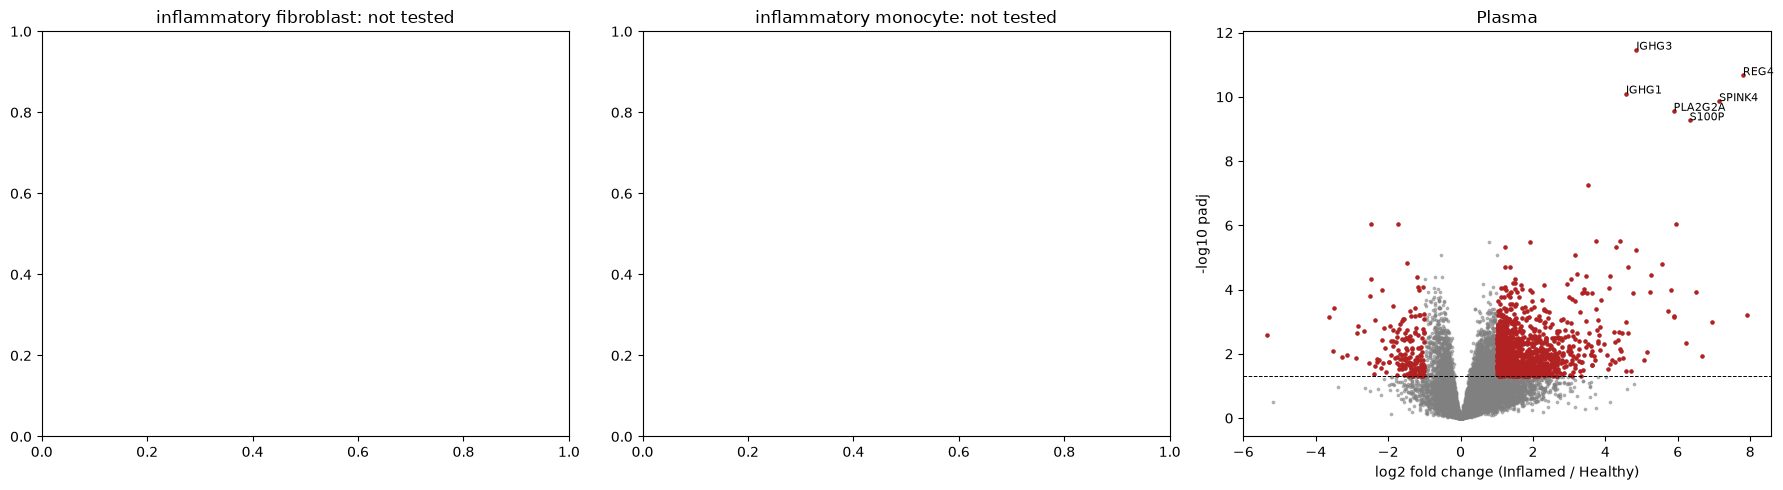

In [12]:
# Volcano plots for the headline populations
import matplotlib.pyplot as plt

def pick(substr):
    return next((l for l in results if substr.lower() in l.lower()), None)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, substr in zip(axes, ["inflammatory fibroblast", "inflammatory monocyte", "plasma"]):
    label = pick(substr)
    if label is None:
        ax.set_title(f"{substr}: not tested"); continue
    r = results[label].copy()
    r["neglogp"] = -np.log10(r["padj"].clip(lower=1e-300))
    sig = (r["padj"] < 0.05) & (r["log2FoldChange"].abs() > 1)
    ax.scatter(r["log2FoldChange"], r["neglogp"], s=3, c="grey", alpha=0.5)
    ax.scatter(r.loc[sig, "log2FoldChange"], r.loc[sig, "neglogp"], s=5, c="firebrick")
    for g in r[sig].head(6).index:
        ax.annotate(g, (r.loc[g, "log2FoldChange"], r.loc[g, "neglogp"]), fontsize=8)
    ax.axhline(-np.log10(0.05), ls="--", c="k", lw=0.7)
    ax.set_xlabel("log2 fold change (Inflamed / Healthy)")
    ax.set_ylabel("-log10 padj")
    ax.set_title(label)
plt.tight_layout()
plt.savefig("../figures/volcano_key_populations.png", dpi=150)
plt.show()


In [13]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

for label, m in meta.groupby("label"):
    if "inflammatory" not in label.lower():
        continue
    m2 = m[m["condition"].isin(["Inflamed", "Non-inflamed"])]
    conds = m2["condition"].value_counts()
    if conds.get("Inflamed", 0) < 3 or conds.get("Non-inflamed", 0) < 3:
        print(label, "still not enough:", dict(conds)); continue
    cdf = pb_df.loc[m2.index].sparse.to_dense().astype(int)
    cdf = cdf.loc[:, (cdf >= 10).sum(axis=0) >= 3]
    dds = DeseqDataSet(counts=cdf, metadata=m2[["condition"]], design_factors="condition")
    dds.deseq2()
    stats = DeseqStats(dds, contrast=["condition", "Inflamed", "Non-inflamed"])
    stats.summary()
    res = stats.results_df.sort_values("padj")
    res.to_csv(f"../results/deseq2_inflamed_vs_noninflamed_{label.replace(' ', '_').replace('+', 'pos')}.csv")
    print(label, "DE genes:", (res["padj"] < 0.05).sum(), "| top:", res[res["padj"] < 0.05].head(5).index.tolist())


Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 1.15 seconds.

Fitting dispersion trend curve...
... done in 0.23 seconds.

Fitting MAP dispersions...
... done in 1.28 seconds.

Fitting LFCs...
... done in 1.33 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 21 outlier genes.

Fitting dispersions...
... done in 0.01 seconds.

Fitting MAP dispersions...
... done in 0.01 seconds.

Fitting LFCs...
... done in 0.01 seconds.

Running Wald tests...
... done in 0.50 seconds.



Log2 fold change & Wald test p-value: condition Inflamed vs Non-inflamed
            baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
A1BG-AS1    4.692555       -0.733776  0.515415 -1.423660  0.154545  0.999827
A2M       297.852471       -0.854668  0.444075 -1.924601  0.054279  0.999827
A4GALT     37.285279        0.067066  0.286190  0.234342  0.814720  0.999827
AAAS       15.464935        0.126297  0.382119  0.330517  0.741009  0.999827
AACS        4.298296        0.682924  0.645946  1.057248  0.290399  0.999827
...              ...             ...       ...       ...       ...       ...
ZWINT       5.051136        0.057118  0.887267  0.064375  0.948672  0.999827
ZYG11B      5.686514       -0.115310  0.553026 -0.208508  0.834832  0.999827
ZYX        42.126383        0.078998  0.255158  0.309605  0.756861  0.999827
ZZEF1       4.072862        0.730990  0.565051  1.293671  0.195779  0.999827
ZZZ3        4.436549       -0.318318  0.535842 -0.594052  0.552477  0.999827

[9

Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 0.48 seconds.

Fitting dispersion trend curve...
... done in 0.08 seconds.

Fitting MAP dispersions...
... done in 0.51 seconds.

Fitting LFCs...
... done in 0.35 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 6 outlier genes.

Fitting dispersions...
... done in 0.01 seconds.

Fitting MAP dispersions...
... done in 0.01 seconds.

Fitting LFCs...
... done in 0.01 seconds.

Running Wald tests...


Log2 fold change & Wald test p-value: condition Inflamed vs Non-inflamed
              baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
AAED1         7.053278       -0.380014  0.510594 -0.744259  0.456720  0.999878
AAMP          6.897465        0.324469  0.483170  0.671544  0.501874  0.999878
ABHD2         4.271738       -0.387257  0.648478 -0.597178  0.550388  0.999878
ABHD5         5.342222        0.414739  0.680805  0.609190  0.542399  0.999878
ABI1          6.755114       -0.153080  0.434144 -0.352602  0.724387  0.999878
...                ...             ...       ...       ...       ...       ...
ZSCAN16-AS1   2.864714       -0.337127  0.969686 -0.347666  0.728091  0.999878
ZSWIM6        3.448735       -0.186377  0.740747 -0.251607  0.801345  0.999878
ZSWIM7        6.167342        0.639657  0.697351  0.917266  0.359003  0.999878
ZYX          15.603136        0.086714  0.376847  0.230103  0.818012  0.999878
ZZEF1         0.827516       -0.658290  1.203153 -0.547137

... done in 0.25 seconds.



In [17]:
print(meta[meta["label"].str.contains("nflammatory")].groupby("label")["n_cells"].median())


label
Inflammatory Fibroblasts    66.0
Inflammatory Monocytes      31.0
Name: n_cells, dtype: float64


In [18]:
import scipy.sparse as sp
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

key2 = (obs["Subject"].astype(str) + "|" + obs["condition"].astype(str) + "|" + obs["Major_l2"].astype(str))
codes2, uniques2 = pd.factorize(key2)
ind2 = sp.csr_matrix((np.ones(len(codes2), dtype=np.float32), (codes2, np.arange(len(codes2)))), shape=(len(uniques2), len(codes2)))
pb2 = pd.DataFrame.sparse.from_spmatrix(ind2 @ counts, index=uniques2, columns=adata.var_names)
meta2 = pd.DataFrame([u.split("|", 2) for u in uniques2], columns=["Subject", "condition", "label"], index=uniques2)

watch = ["IL11", "IL13RA2", "IL24", "CHI3L1", "OSM", "OSMR", "IL1B", "S100A8", "S100A9"]
for comp in ["Stromal", "Myeloid"]:
    m2 = meta2[meta2["label"] == comp]
    cdf = pb2.loc[m2.index].sparse.to_dense().astype(int)
    cdf = cdf.loc[:, (cdf >= 10).sum(axis=0) >= 3]
    dds = DeseqDataSet(counts=cdf, metadata=m2[["condition"]], design_factors="condition")
    dds.deseq2()
    stats = DeseqStats(dds, contrast=["condition", "Inflamed", "Healthy"])
    stats.summary()
    res = stats.results_df.sort_values("padj")
    print(comp, "DE genes:", (res["padj"] < 0.05).sum())
    print(res.loc[res.index.intersection(watch), ["log2FoldChange", "padj"]])


Fitting size factors...
... done in 0.02 seconds.

Fitting dispersions...
... done in 1.98 seconds.

Fitting dispersion trend curve...
... done in 0.30 seconds.

Fitting MAP dispersions...
... done in 2.41 seconds.

Fitting LFCs...
... done in 1.94 seconds.

Calculating cook's distance...
... done in 0.05 seconds.

Replacing 112 outlier genes.

Fitting dispersions...
... done in 0.07 seconds.

Fitting MAP dispersions...
... done in 0.07 seconds.

Fitting LFCs...
... done in 0.06 seconds.

Running Wald tests...
... done in 0.71 seconds.



Log2 fold change & Wald test p-value: condition Inflamed vs Healthy
                 baseMean  log2FoldChange     lfcSE      stat    pvalue  \
A1BG-AS1        12.197591       -1.072622  0.245499 -4.369157  0.000012   
A2M           1526.192925       -0.445271  0.192927 -2.307973  0.021001   
A2M-AS1          2.400513       -0.518361  0.512000 -1.012424  0.311335   
A4GALT          77.302941        0.078561  0.187437  0.419134  0.675118   
AAAS            35.051022       -0.427073  0.148287 -2.880046  0.003976   
...                   ...             ...       ...       ...       ...   
ZYX             85.302358        0.518879  0.191284  2.712610  0.006676   
ZZEF1           14.205984        0.315637  0.274369  1.150411  0.249975   
ZZZ3            15.948037        0.574600  0.304937  1.884327  0.059521   
hsa-mir-6080     6.927036        1.069846  0.305250  3.504817  0.000457   
hsa-mir-8072     7.073451       -0.509852  0.308745 -1.651371  0.098663   

                  padj  
A1BG-A

Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 1.62 seconds.

Fitting dispersion trend curve...
... done in 0.27 seconds.

Fitting MAP dispersions...
... done in 2.03 seconds.

Fitting LFCs...
... done in 1.29 seconds.

Calculating cook's distance...
... done in 0.04 seconds.

Replacing 91 outlier genes.

Fitting dispersions...
... done in 0.05 seconds.

Fitting MAP dispersions...
... done in 0.05 seconds.

Fitting LFCs...
... done in 0.06 seconds.

Running Wald tests...


Log2 fold change & Wald test p-value: condition Inflamed vs Healthy
                baseMean  log2FoldChange     lfcSE      stat    pvalue  \
7SK             1.218693        2.095967  0.683127  3.068196  0.002154   
A1BG-AS1        4.106641       -0.566138  0.329620 -1.717547  0.085879   
A2M           149.324768       -0.666372  0.408326 -1.631962  0.102688   
A2M-AS1         2.637651        1.754414  0.755268  2.322902  0.020184   
A4GALT          1.953714       -0.187374  0.713057 -0.262775  0.792724   
...                  ...             ...       ...       ...       ...   
ZYX            69.801920       -0.073131  0.186197 -0.392760  0.694497   
ZZEF1          12.508538       -0.031644  0.343140 -0.092218  0.926525   
ZZZ3            7.920025        0.757643  0.359409  2.108025  0.035029   
hsa-mir-6080    5.559997        0.142641  0.273292  0.521936  0.601715   
hsa-mir-8072    1.883592        0.702941  0.458187  1.534179  0.124986   

                  padj  
7SK               

... done in 0.60 seconds.



## 3. Anti-TNF non-response module

Two readouts per sample, by condition:
- **Abundance** — inflammatory fibroblasts as a share of stromal cells; inflammatory monocytes as a share of myeloid cells.
- **Program score** — mean module-gene score (scanpy score_genes) within each population.

Reference biology: Smillie et al., Cell 2019 (inflammatory fibroblasts, IL13RA2+IL11+);
Martin et al., Cell 2019 (GIMATS / OSM axis and anti-TNF resistance).


In [14]:
fib_label = next(l for l in adata.obs["author_label"].unique() if "inflammatory fibroblast" in l.lower())
mono_label = next(l for l in adata.obs["author_label"].unique() if "inflammatory monocyte" in l.lower())
print("fibroblast label:", fib_label, "| monocyte label:", mono_label)

obs = adata.obs
def abundance(target_label, compartment_l2):
    comp = obs[obs["Major_l2"] == compartment_l2]
    tot = comp.groupby(["Subject", "condition"]).size()
    tgt = comp[comp["author_label"] == target_label].groupby(["Subject", "condition"]).size()
    out = (tgt / tot).fillna(0.0).rename("fraction").reset_index()
    return out

ab_fib = abundance(fib_label, "Stromal")
ab_mono = abundance(mono_label, "Myeloid")
print(ab_fib.groupby("condition")["fraction"].median())
print(ab_mono.groupby("condition")["fraction"].median())


fibroblast label: Inflammatory Fibroblasts | monocyte label: Inflammatory Monocytes
condition
Healthy         0.0
Inflamed        0.0
Non-inflamed    0.0
Name: fraction, dtype: float64
condition
Healthy         0.000000
Inflamed        0.006492
Non-inflamed    0.000000
Name: fraction, dtype: float64


In [15]:
# Program scores
fib_genes = ["IL11", "IL13RA2", "IL24", "CHI3L1", "MMP3", "MMP10", "IL6", "CXCL1", "CXCL5"]
mono_genes = ["OSM", "OSMR", "IL1B", "IL6", "TNF", "S100A8", "S100A9"]
for name, genes in [("fib_program", fib_genes), ("mono_program", mono_genes)]:
    present = [g for g in genes if g in adata.var_names]
    print(name, "genes present:", present)
    sc.tl.score_genes(adata, present, score_name=name)

def sample_scores(label, score_col):
    sub = adata.obs[adata.obs["author_label"] == label]
    return (sub.groupby(["Subject", "condition"])[score_col].mean()
            .rename("score").reset_index())

sc_fib = sample_scores(fib_label, "fib_program")
sc_mono = sample_scores(mono_label, "mono_program")
print(sc_fib.groupby("condition")["score"].median())
print(sc_mono.groupby("condition")["score"].median())


fib_program genes present: ['IL11', 'IL13RA2', 'CHI3L1', 'MMP3', 'MMP10', 'IL6', 'CXCL1', 'CXCL5']
mono_program genes present: ['OSM', 'OSMR', 'IL1B', 'IL6', 'TNF', 'S100A8', 'S100A9']
condition
Healthy         0.086582
Inflamed        0.373598
Non-inflamed    0.142309
Name: score, dtype: float64
condition
Healthy         0.665889
Inflamed        1.068268
Non-inflamed    1.168437
Name: score, dtype: float64


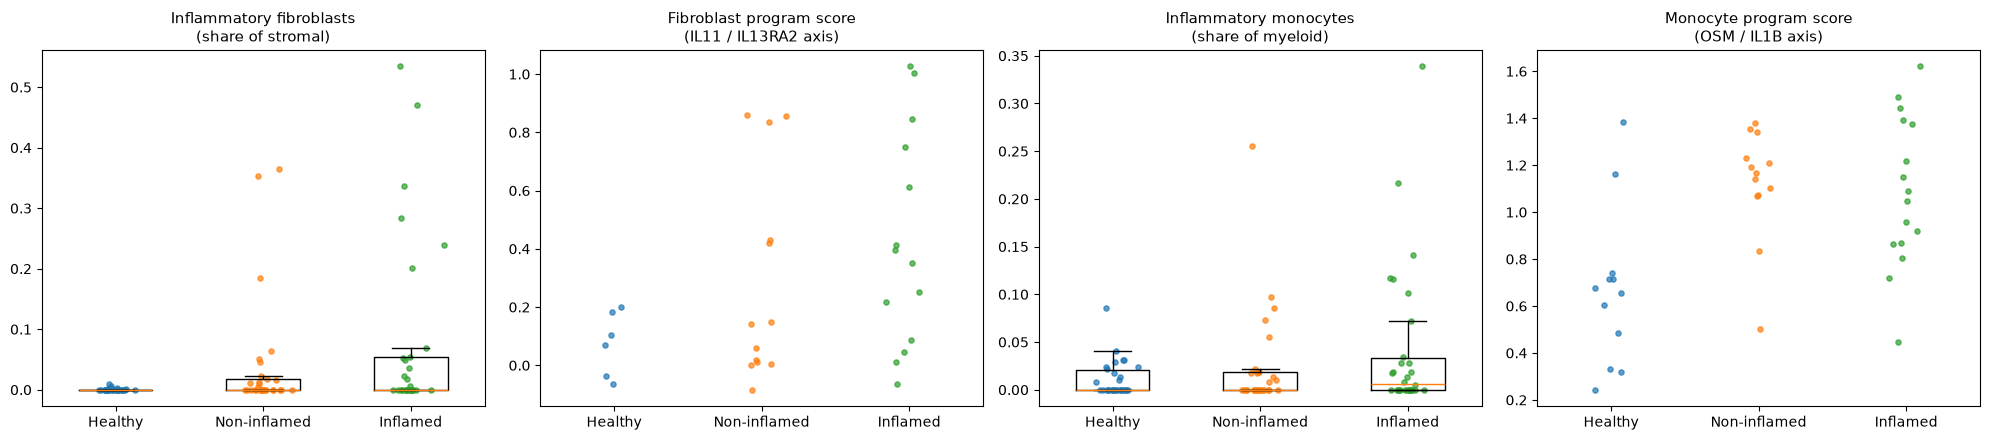

In [16]:
# Translational summary figure: abundance + program score, by condition
import matplotlib.pyplot as plt

order = ["Healthy", "Non-inflamed", "Inflamed"]
def strip(ax, df, col, title):
    for i, c in enumerate(order):
        v = df[df["condition"] == c][col]
        ax.boxplot(v, positions=[i], widths=0.5, showfliers=False)
        ax.scatter(np.random.normal(i, 0.06, len(v)), v, s=14, alpha=0.7)
    ax.set_xticks(range(3)); ax.set_xticklabels(order)
    ax.set_title(title, fontsize=11)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
strip(axes[0], ab_fib, "fraction", "Inflammatory fibroblasts\n(share of stromal)")
strip(axes[1], sc_fib, "score", "Fibroblast program score\n(IL11 / IL13RA2 axis)")
strip(axes[2], ab_mono, "fraction", "Inflammatory monocytes\n(share of myeloid)")
strip(axes[3], sc_mono, "score", "Monocyte program score\n(OSM / IL1B axis)")
plt.tight_layout()
plt.savefig("../figures/antitnf_module_summary.png", dpi=150)
plt.show()


## Read-out (fill in after running)

- Which labels carry the most DE genes, and do the inflammatory fibroblast / monocyte
  programs sit at the top of their own volcano plots (IL11, IL13RA2, OSM, IL1B)?
- Abundance and program score should both rise Healthy -> Non-inflamed -> Inflamed
  if the module behaves as published. That gradient is the figure a translational
  audience reads first: a disease-activity-linked, drug-resistance-associated cell state.

Next: notebook 04 — cell-cell communication (LIANA) around the OSM-OSMR and IL11 axes;
notebook 05 — the same module in R/Seurat for the cross-platform record.

- At compartment level the fibroblast axis is unmistakable: 3,568 DE genes in stromal
  cells, with IL13RA2 (+6.3 log2FC) and CHI3L1 (+5.1) among the top signals and the
  OSM receptor OSMR significantly up - the monocyte OSM -> fibroblast OSMR circuit
  is visible across compartments.
